This now uses srcB/dataprep.py
- difference : it passes lsit of horizons as dynamic list . so you dont have to open backend to modify the list.

In [3]:
import pandas as pd 
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")

### Data (GARCH avg version)

### Production of X_by_year (avg mfiv version)(versatile for all)


In [ ]:
import pandas as pd
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2022, 2023, 2024, 2025]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")


In [5]:
import sys
sys.path.insert(0 , "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")

In [6]:
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index("date_time")
    df_raw_by_year[y] = df_raw_by_year[y].set_index("date_time")

In [7]:
for y in YEARS:
    d_btc_raw_by_year[y].index = pd.to_datetime(d_btc_raw_by_year[y].index)
    df_raw_by_year[y].index = pd.to_datetime(df_raw_by_year[y].index)

In [8]:
from srcB.ddout import derivative_data, datetime_to_timestamp, timestamp_to_datetime

In [9]:
## SKIP FROM NOW, LOAD AFTER SECOND PLOT 
### Data Prep
from srcB.dataPrep import dataprep
d_btc_by_year = {}
df_by_year = {}

for y in YEARS:
    d_btc = d_btc_raw_by_year[y]
    df    = df_raw_by_year[y]

    # prep = dataprep(d_btc=d_btc, df=df)
    # prep = dataprep(d_btc=d_btc, df=df, horizons=[3, 4, 10, 24])
    prep = dataprep(d_btc=d_btc, df=df, horizons=list(range(2, 577))) # save massive grid.
    d_btc_by_year[y], df_by_year[y] = prep.run_all()


In [18]:
# load back COPIED FROM BELOW 

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/df_by_year_all.pkl", "rb") as f :
    df_by_year = pickle.load(f)


In [12]:
d_btc_by_year[2022].columns

Index(['timestamp', 'open', 'high', 'low', 'Close', 'volume', 'cost', 'rfr',
       'r', 'F2',
       ...
       'F567', 'F568', 'F569', 'F570', 'F571', 'F572', 'F573', 'F574', 'F575',
       'F576'],
      dtype='str', length=584)

148 unique rfr values out of 8785
8556 unique 382 values out of 8785


<Axes: title={'center': 'rfr over 2021'}, xlabel='date_time'>

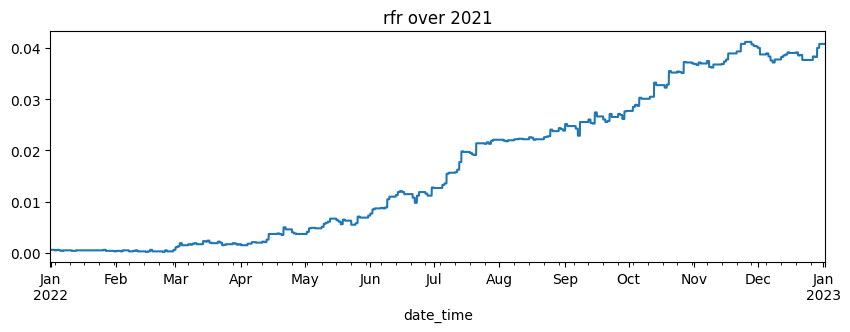

In [13]:
d_c = d_btc_by_year[2022]
print(d_c["rfr"].nunique(), "unique rfr values out of", len(d_c))
print(d_c["F382"].nunique(), "unique 382 values out of", len(d_c))
d_c["rfr"].plot(figsize=(10,3), title="rfr over 2021")

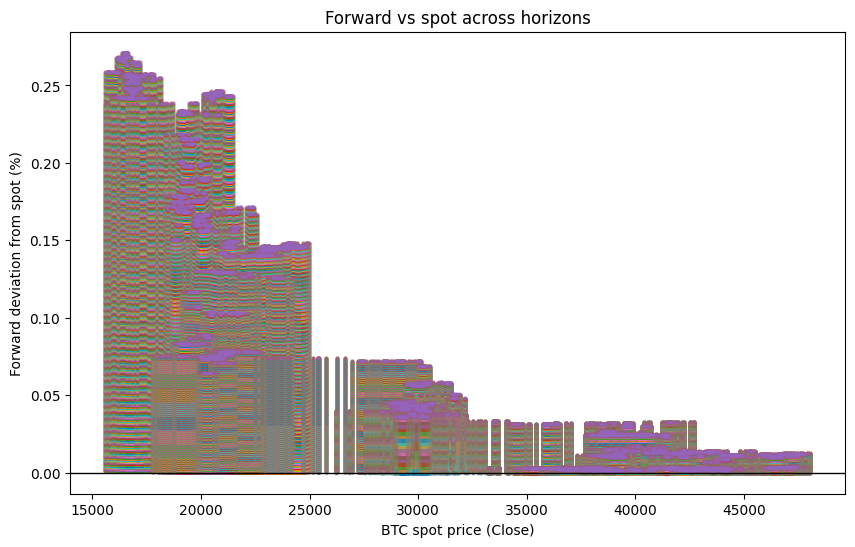

In [15]:
import matplotlib.pyplot as plt

d = d_btc_by_year[2022]

# HOURS = [3, 7, 11, 16, 22, 29, 37, 46, 56, 67, 79, 92, 106, 121, 137, 154, 172, 191]
# HOURS = [191, 382, 573, 764] 
# HOURS=[3, 4, 10, 24] # only testing
HOURS = list(range(2, 577))

fig, ax = plt.subplots(figsize=(10, 6))

for H in HOURS:
    pct_dev = (d[f"F{H}"] - d["Close"]) / d["Close"] * 100  # % forward is above/below spot
    ax.scatter(d["Close"], pct_dev, s=4, alpha=0.3, label=f"F{H}")

ax.axhline(0, color="black", linewidth=1)  # 0% = forward equals spot
ax.set_xlabel("BTC spot price (Close)")
ax.set_ylabel("Forward deviation from spot (%)")
ax.set_title("Forward vs spot across horizons")
# ax.legend(markerscale=3, fontsize=8, ncol=2)
plt.show()

In [16]:
import os, sys
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data", exist_ok = True)

In [17]:

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/d_btc_by_year_all.pkl", "wb") as f :
    pickle.dump(d_btc_by_year, f)

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/df_by_year_all.pkl", "wb") as f :
    pickle.dump(df_by_year, f)

In [ ]:
# # load back ORIGINAL

# import pickle
# with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/d_btc_by_year_all.pkl", "rb") as f :
#     d_btc_by_year = pickle.load(f)

# import pickle
# with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/ready_data/df_by_year_all.pkl", "rb") as f :
#     df_by_year = pickle.load(f)

- BTC perpetual funding rate, annualized — a rate determined entirely by positioning in the BTC perp market (how much longs pay shorts, or vice versa, every 8 hours on Deribit), reflecting sentiment/leverage imbalance, not any monetary policy or true "risk-free" concept.

### BTC futures data download

In [19]:
import pandas as pd

df_fut_raw_by_year = {}


In [11]:
### TOO MEMORY INTENSIVE, JUST LOAD AND EXECUTED BELOW THIS CELL
# YEARS = [2019, 2020, 2021]
# for y in YEARS:
#     df_fut_raw_by_year[y] = pd.read_parquet(f"/Users/shah/CODE_BOOK_4/ROUGH/ROUGH/futures_data_{y}.parquet")

In [20]:
### PREPARE d_fut
d_fut = {}

for y in YEARS:

    fut = pd.read_parquet(
        f"/Users/shah/CODE_BOOK_4/ROUGH/ROUGH/futures_data_{y}.parquet",
        columns=["timestamp", "instrument_name", "mark_price"]
    )

    fut = fut.loc[
        (fut["instrument_name"] != "BTC-PERPETUAL")
        & fut["mark_price"].notna()
    ]

    fut["hour"] = (
        pd.to_datetime(fut["timestamp"], unit="ms").dt.floor("h")
        + pd.Timedelta(hours=1)
    )

    maturity_map = {
        name: pd.to_datetime(
            name.split("-")[1],
            format="%d%b%y"
        ) + pd.Timedelta(hours=8)
        for name in fut["instrument_name"].unique()
    }

    fut["maturity"] = fut["instrument_name"].map(maturity_map)

    idx = fut.groupby(["hour", "maturity"])["timestamp"].idxmax()

    d_fut[y] = (
        fut.loc[idx, ["hour", "maturity", "mark_price"]]
        .rename(columns={"mark_price": "F"})
        .sort_values(["hour", "maturity"])
        .reset_index(drop=True)
    )

    del fut

In [21]:
sys.modules.pop("srcB", None)

<module 'srcB' (namespace) from ['/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration/srcB']>

In [22]:
from srcB.interpol_2 import MFIVPipeline

In [23]:
### PRECOMPUTE MFIV AT ACTUAL OPTION MATURITIES

from srcB.interpol_2 import MFIVPipeline

q = 0.0

MFIV_maturity_by_year = {}

for y in YEARS:

    d_c = d_btc_by_year[y].copy()
    df_c = df_by_year[y].copy()

    pipe = MFIVPipeline( df=df_c, d_btc=d_c, d_fut=d_fut[y], q=q)

    pipe.build_surfaces()

    MFIV_maturity_by_year[y] = ( pipe.precompute_mfiv_maturities() )
    
    MFIV_maturity_by_year[y].to_parquet( f"MFIV_maturity_{y}.parquet", index=False)


100%|██████████| 8782/8782 [00:14<00:00, 590.51it/s]


In [26]:
### Prepare MFIV with multiple horizons

from srcB.interpol_2 import MFIVPipeline
import numpy as np
import pandas as pd

MFIVS = list(range(2, 577))

X_by_year = {}
MFIV_by_year = {}

for y in YEARS:

    d_c = d_btc_by_year[y].copy()

    idx = ( d_c.index.tz_localize("UTC") if d_c.index.tz is None else d_c.index.tz_convert("UTC"))

    rt = d_c["r"]

    pipe = MFIVPipeline(
        df=df_by_year[y],
        d_btc=d_c,
        d_fut=d_fut[y],
        q=q
    )

    pipe.mfiv_maturity = MFIV_maturity_by_year[y]

    MFIV_byH = pipe.compute_mfiv_byH(
        H_LIST=MFIVS
    )

    MFIV_by_year[y] = MFIV_byH
    cols = { "rt": rt.values }

    for H in MFIVS:
        mf = MFIV_byH[H].reindex(idx.tz_convert(None))

        cols[f"bsIV_{H}"] = mf["bsIV"].to_numpy()
        cols[f"MFIV_{H}"] = mf["MFIV"].to_numpy()

    X_by_year[y] = pd.DataFrame(
        cols,
        index=idx
    )

100%|██████████| 8782/8782 [00:21<00:00, 401.67it/s]


In [ ]:
################# 30 hour estimated.
# ### Prepare MFIV with multiple horizons

# from srcB.interpol_2 import MFIVPipeline 
# import numpy as np
# import pandas as pd

# q = 0.0

# MFIVS = list(range(2, 577))

# X_by_year = {}
# MFIV_by_year = {}

# for y in YEARS:
#     d_c = d_btc_by_year[y].copy()
#     df_c = df_by_year[y].copy()

#     idx = (
#         d_c.index.tz_localize("UTC")
#         if d_c.index.tz is None
#         else d_c.index.tz_convert("UTC")
#     )

#     rt = d_c["r"]

#     pipe = MFIVPipeline(
#         df=df_c,
#         d_btc=d_c,
#         d_fut=d_fut[y],
#         q=q
#     )

#     pipe.build_surfaces()

#     MFIV_byH = pipe.compute_mfiv_byH(H_LIST=MFIVS)
#     MFIV_by_year[y] = MFIV_byH

#     X_by_year[y] = pd.DataFrame(
#         {
#             "rt": rt.values
#         },
#         index=idx
#     )

#     for H in MFIVS:
#         mf = MFIV_byH[H].reindex(idx.tz_convert(None))
#         X_by_year[y][f"bsIV_{H}"] = mf["bsIV"].to_numpy()
#         X_by_year[y][f"MFIV_{H}"] = mf["MFIV"].to_numpy()

In [24]:
import os
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/x_by_year_fut", exist_ok = True)


In [27]:
# one prelimary save for safety 
# the "all" keyword stands for all MFIVs. Just indicating a finer grid of MFIVS
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/x_by_year_fut/x_by_year.pkl", "wb") as f:
    pickle.dump(X_by_year, f)

In [28]:
eps = 1e-16

# MFIVS = [191, 382, 573, 764] 
MFIVS = list(range(2, 577))

for y in YEARS:
    for H in MFIVS:
        cols = [f"bsIV_{H}", f"MFIV_{H}"]

        X_by_year[y][cols] = np.exp(
            np.log(
                X_by_year[y][cols].clip(lower=eps)
            ).interpolate(
                method="linear",
                limit_direction="both"
            )
        )

In [29]:
## NOT JUST COMMENTED OUT, NOT RUN ALTOGETHOR. CONFIRMED
# # CONVERT TO HOURLY 
# YEARS = [2019, 2020, 2021]
# for y in YEARS:
#     X_by_year[y][[f"MFIV_{H}" for H in MFIVS]] /= 8760.0

In [28]:
for y in YEARS:
    print(y, X_by_year[y].shape, "NaNs:", X_by_year[y].isna().sum().sum()/X_by_year[y].size)
    display(X_by_year[y].describe().loc[["mean", "std", "min", "max"]])

2019 (8785, 1152) NaNs: 0.0006852550116992349


,rt,bsIV_2,MFIV_2,bsIV_3,MFIV_3,bsIV_4,MFIV_4,bsIV_5,MFIV_5,bsIV_6,...,MFIV_572,bsIV_573,MFIV_573,bsIV_574,MFIV_574,bsIV_575,MFIV_575,bsIV_576,MFIV_576,mfiv_avg
mean,0.000076,0.716155,0.599493,0.716155,0.599218,0.716155,0.598904,0.716155,0.597717,0.716155,...,0.525160,0.721765,0.525244,0.721765,0.525229,0.721765,0.525214,0.721771,0.524764,0.771483
std,0.007794,0.221040,0.473004,0.221040,0.471268,0.221040,0.468759,0.221040,0.454394,0.221040,...,0.329334,0.207222,0.329407,0.207222,0.329396,0.207222,0.329384,0.207219,0.329723,0.446300
min,-0.121632,0.188201,0.076112,0.188201,0.076112,0.188201,0.076112,0.188201,0.076112,0.188201,...,0.061416,0.100262,0.061416,0.100262,0.061416,0.100262,0.061416,0.100262,0.061416,0.061416
max,0.122628,3.761311,10.257601,3.761311,10.257601,3.761311,10.257601,3.761311,9.899940,3.761311,...,9.899940,1.873236,9.899940,1.873236,9.899940,1.873236,9.899940,1.873236,9.899940,9.899940


2020 (8809, 1152) NaNs: 0.00043181058513389086


,rt,bsIV_2,MFIV_2,bsIV_3,MFIV_3,bsIV_4,MFIV_4,bsIV_5,MFIV_5,bsIV_6,...,MFIV_572,bsIV_573,MFIV_573,bsIV_574,MFIV_574,bsIV_575,MFIV_575,bsIV_576,MFIV_576,mfiv_avg
mean,0.000160,0.640811,0.593473,0.640811,0.593473,0.640811,0.593473,0.640811,0.593473,0.640811,...,0.522064,0.641752,0.522022,0.641693,0.522400,0.641797,0.522609,0.641971,0.522084,0.648098
std,0.008337,0.303907,0.669973,0.303907,0.669973,0.303907,0.669973,0.303907,0.669973,0.303907,...,0.425471,0.225315,0.425432,0.225341,0.425463,0.225251,0.425603,0.225252,0.424226,0.598253
min,-0.245568,0.315360,0.073152,0.315360,0.073152,0.315360,0.073152,0.315360,0.073152,0.315360,...,0.073152,0.291475,0.073152,0.291475,0.073152,0.291475,0.073152,0.291475,0.073152,0.072212
max,0.148535,3.696041,8.309873,3.696041,8.309873,3.696041,8.309873,3.696041,8.309873,3.696041,...,5.628699,2.633019,5.628699,2.633019,5.628699,2.633019,5.628699,2.633019,5.628699,6.582220


2021 (8785, 1152) NaNs: 0.0002228190412951369


,rt,bsIV_2,MFIV_2,bsIV_3,MFIV_3,bsIV_4,MFIV_4,bsIV_5,MFIV_5,bsIV_6,...,MFIV_572,bsIV_573,MFIV_573,bsIV_574,MFIV_574,bsIV_575,MFIV_575,bsIV_576,MFIV_576,mfiv_avg
mean,0.000056,0.883454,0.976665,0.883454,0.976665,0.883454,0.976665,0.883454,0.976665,0.883454,...,0.836362,0.872991,0.836266,0.872860,0.836450,0.872836,0.836317,0.872883,0.836377,0.932468
std,0.009599,0.253857,0.620425,0.253857,0.620425,0.253857,0.620425,0.253857,0.620425,0.253857,...,0.388431,0.179047,0.388417,0.179013,0.388411,0.178985,0.388327,0.178952,0.388347,0.475989
min,-0.175820,0.370782,0.193445,0.370782,0.193445,0.370782,0.193445,0.370782,0.193445,0.370782,...,0.155260,0.397240,0.155260,0.397240,0.155260,0.397240,0.155260,0.397240,0.155260,0.155260
max,0.145399,4.171220,8.840568,4.171220,8.840568,4.171220,8.840568,4.171220,8.840568,4.171220,...,3.070777,2.512190,3.070777,2.512190,3.070777,2.512190,3.070777,2.512190,3.070777,3.732491


corresponds to annualized vol for eg.  sqrt(MFIV) = sqrt(0.93) = 0.6


In [30]:
### COMPUTE AVG MFIV

for y in YEARS:
    # X_by_year[y]["mfiv_avg"] = X_by_year[y][[f"MFIV_{H}" for H in MFIVS]].mean(axis=1)
    X_by_year[y] = pd.concat([
        X_by_year[y], 
        X_by_year[y][[f"MFIV_{H}" for H in MFIVS]].mean(axis=1).to_frame("mfiv_avg")
    ], axis = 1)

In [31]:

os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/x_by_year_fut", exist_ok = True)


In [32]:
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/x_by_year_fut/x_by_year.pkl", "wb") as f:
    pickle.dump(X_by_year, f)

### Load saved X_by_year

In [ ]:

# with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_all/x_by_year.pkl", "rb") as f:
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/OOS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

In [ ]:
X_by_year